<a href="https://colab.research.google.com/github/lucky0786-max/Statistical-Foundation-of-Data-Science/blob/main/8.%20Practical%20/%20practical8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



PRACTICAL:8

*vinayak pant, GF202455018*

Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

Load the Dataset

In [ ]:
df = pd.read_csv("/content/diabetes.csv")
data = df

print(data.head())
print("Shape:", data.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Shape: (768, 9)


Separate Independent and Dependent Variables

In [ ]:
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

print("Independent Variables:")
print(X.columns)

print("\nDependent Variable:")
print("Outcome")

Independent Variables:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

Dependent Variable:
Outcome


Split the Dataset into Training and Testing Data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


Create and Train Decision Tree Classifier

In [ ]:
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7207792207792207


Visualize the Decision Tree

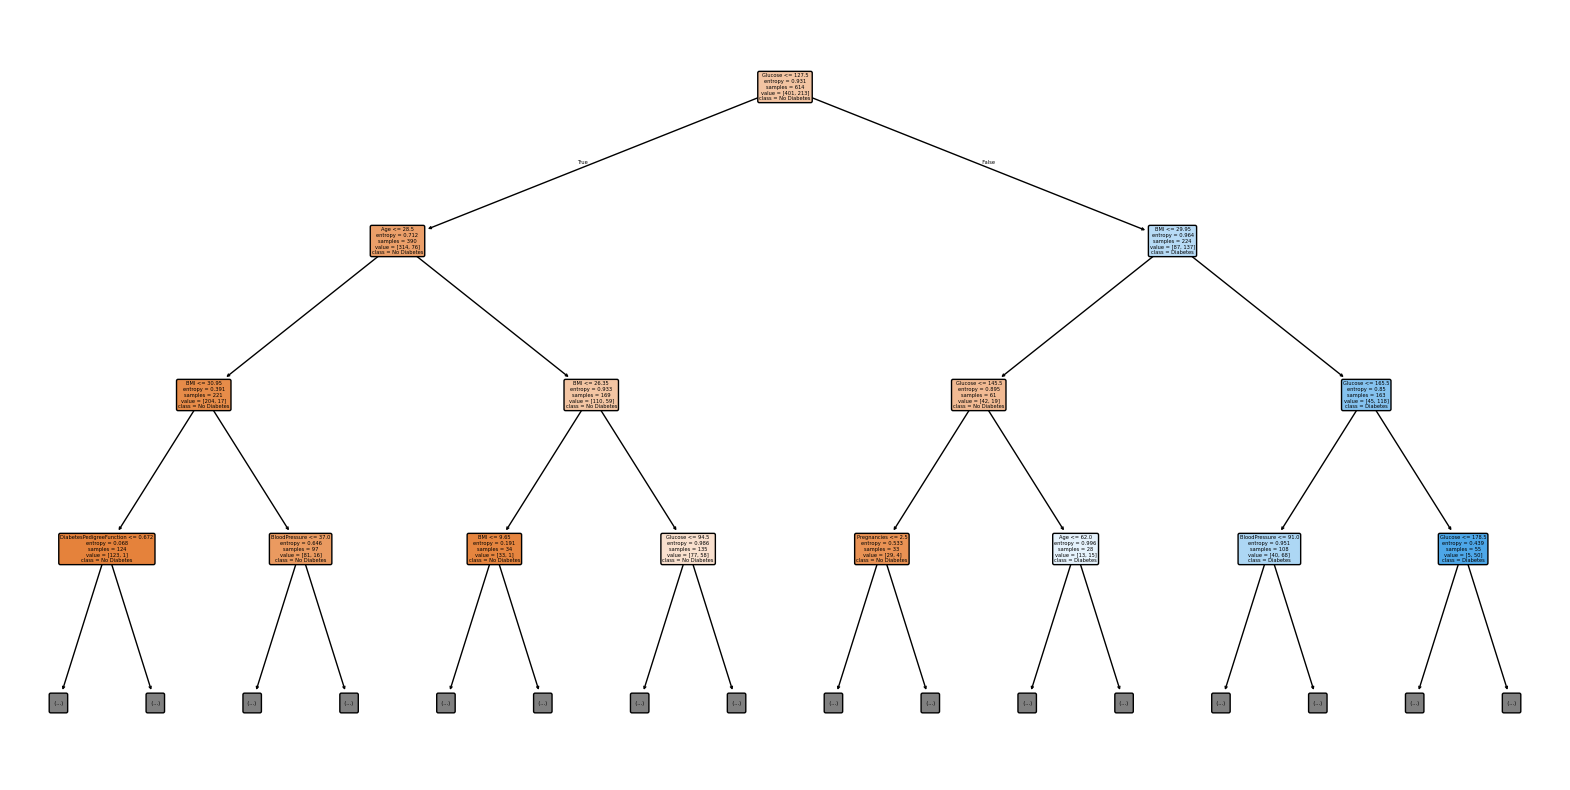

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    max_depth=3
)

plt.show()

Compare Entropy, Information Gain and Gini Index

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Entropy and Information Gain
entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_tree.fit(X_train, y_train)

# Gini Index
gini_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

gini_tree.fit(X_train, y_train)

print("Entropy of root node:", entropy_tree.tree_.impurity[0])

print("Information Gain of root split:",
      entropy_tree.tree_.impurity[0] -
      (
          (entropy_tree.tree_.n_node_samples[1] / entropy_tree.tree_.n_node_samples[0])
          * entropy_tree.tree_.impurity[1]
          +
          (entropy_tree.tree_.n_node_samples[2] / entropy_tree.tree_.n_node_samples[0])
          * entropy_tree.tree_.impurity[2]
      ))

print("Gini Index of root node:", gini_tree.tree_.impurity[0])

print("Root Feature using Entropy:",
      X.columns[entropy_tree.tree_.feature[0]])

print("Root Feature using Gini:",
      X.columns[gini_tree.tree_.feature[0]])

Entropy of root node: 0.9312740341054782
Information Gain of root split: 0.3384886208306732
Gini Index of root node: 0.45312417107873826
Root Feature using Entropy: Glucose
Root Feature using Gini: Glucose


Identify the Root Feature



In [ ]:
print("Selected Root Feature:",
      X.columns[entropy_tree.tree_.feature[0]])

print("Reason: It provides the highest information gain and gives the best separation of diabetic and non-diabetic cases.")

Selected Root Feature: Glucose
Reason: It provides the highest information gain and gives the best separation of diabetic and non-diabetic cases.


conclusion: In this practical, we successfully implemented the Decision Tree Classification algorithm using the Pima Indians Diabetes dataset. We learned how to load data, split it into training and testing sets, train the model, make predictions, visualize the decision tree, and compare Entropy and Gini Index. This practical helped us understand how a Decision Tree is used for classification problems.